# Conditional Diffusion Components

Andrew H. Fagg

Advanced Machine Learning


In [72]:
%reload_ext autoreload
%autoreload 2

import sys

import argparse
import copy
import pickle
import random
from chesapeake_loader4 import *
from diffusion_tools import *

import tensorflow as tf
import keras
from keras.models import Sequential

from keras.layers import Concatenate, UpSampling2D, Add
from keras.layers import Convolution2D, Dense, MaxPooling2D, GlobalMaxPooling2D, Flatten, BatchNormalization, Dropout, SpatialDropout2D
from keras import Input, Model
from matplotlib import colors
from keras.utils import plot_model

#################################################################
# Default plotting parameters
FIGURESIZE=(10,6)
FONTSIZE=18

plt.rcParams['figure.figsize'] = FIGURESIZE
plt.rcParams['font.size'] = FONTSIZE-2

plt.rcParams['xtick.labelsize'] = FONTSIZE-4
plt.rcParams['ytick.labelsize'] = FONTSIZE-4

#################################################################



In [2]:
# Configure the GPU
visible_devices = tf.config.get_visible_devices('GPU')
for device in visible_devices:
    tf.config.experimental.set_memory_growth(device, True)

In [73]:
# Turn off the GPU
tf.config.set_visible_devices([], 'GPU')

In [60]:
patch_size=64
batch_size=8
time_sampling_exponent=0.5
file_base = '/home/fagg/datasets/radiant_earth/pa'

# Linear schedule
beta, alpha, sigma = compute_beta_alpha(50, .0001, .1)



In [61]:
ds, ds_valid =create_diffusion_dataset(base_dir=file_base, patch_size=patch_size, fold=0,
                                        cache_dir=None, repeat=True, shuffle=200, batch_size=batch_size, 
                                       filt='*[9]',
                                       time_sampling_exponent=time_sampling_exponent,
                                    prefetch=2, num_parallel_calls=4,
                                   alpha=alpha)

[64, 64, 26]
Shuffle 200 <class 'int'>
[64, 64, 26]


In [62]:
print(ds)

<_PrefetchDataset element_spec=({'label_input': TensorSpec(shape=(None, 64, 64, 7), dtype=tf.float32, name=None), 'time_input': TensorSpec(shape=(None, 1), dtype=tf.int32, name=None), 'image_input': TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None)}, TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None))>


In [63]:
for i0, i1 in ds.take(1):
    L = i0['label_input']
    t = i0['time_input']
    I = i0['image_input']
    noise = i1
    print(L.shape, t.shape, I.shape, noise.shape)

(8, 64, 64, 7) (8, 1) (8, 64, 64, 3) (8, 64, 64, 3)


2025-04-23 21:17:23.168072: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


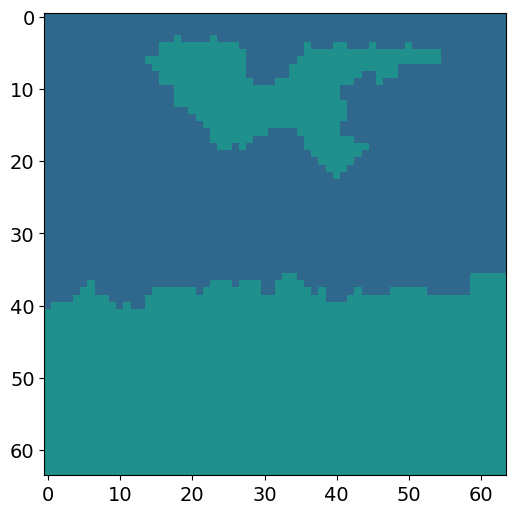

In [64]:
i=0

# Label image
plt.imshow(np.argmax(L.numpy()[i,:,:,:], axis=-1), vmin=0, vmax=6)

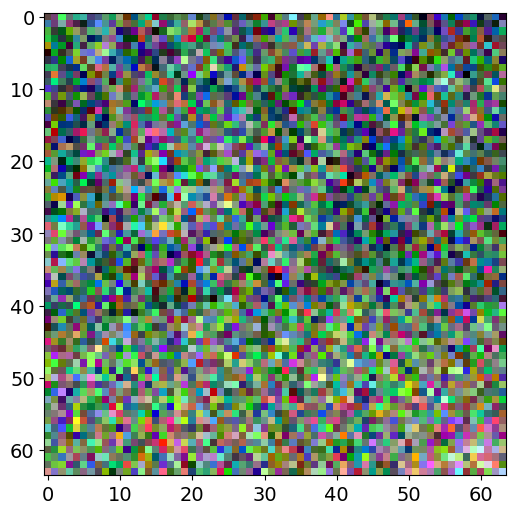

In [65]:
# Noised image
plt.imshow(convert_image(I.numpy()[i,:,:,:]))

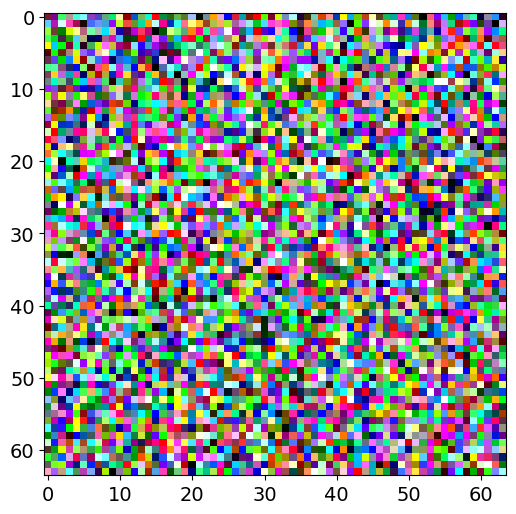

In [66]:
# Noise to predict
plt.imshow(convert_image(noise.numpy()[i,:,:,:]))

In [67]:
# For fun: subtract the noise from the image
img = I.numpy()[i,:,:,:] - 0.3*noise.numpy()[i,:,:,:]

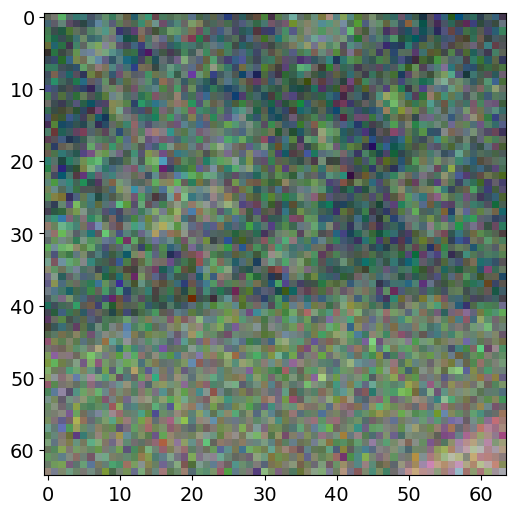

In [68]:
plt.imshow(convert_image(img))

In [69]:
# Timestep indices for each element in the batch
t.numpy()

array([[15],
       [ 8],
       [32],
       [13],
       [ 5],
       [29],
       [34],
       [19]], dtype=int32)

## Visualize Full Batch

2025-04-23 21:18:03.262541: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


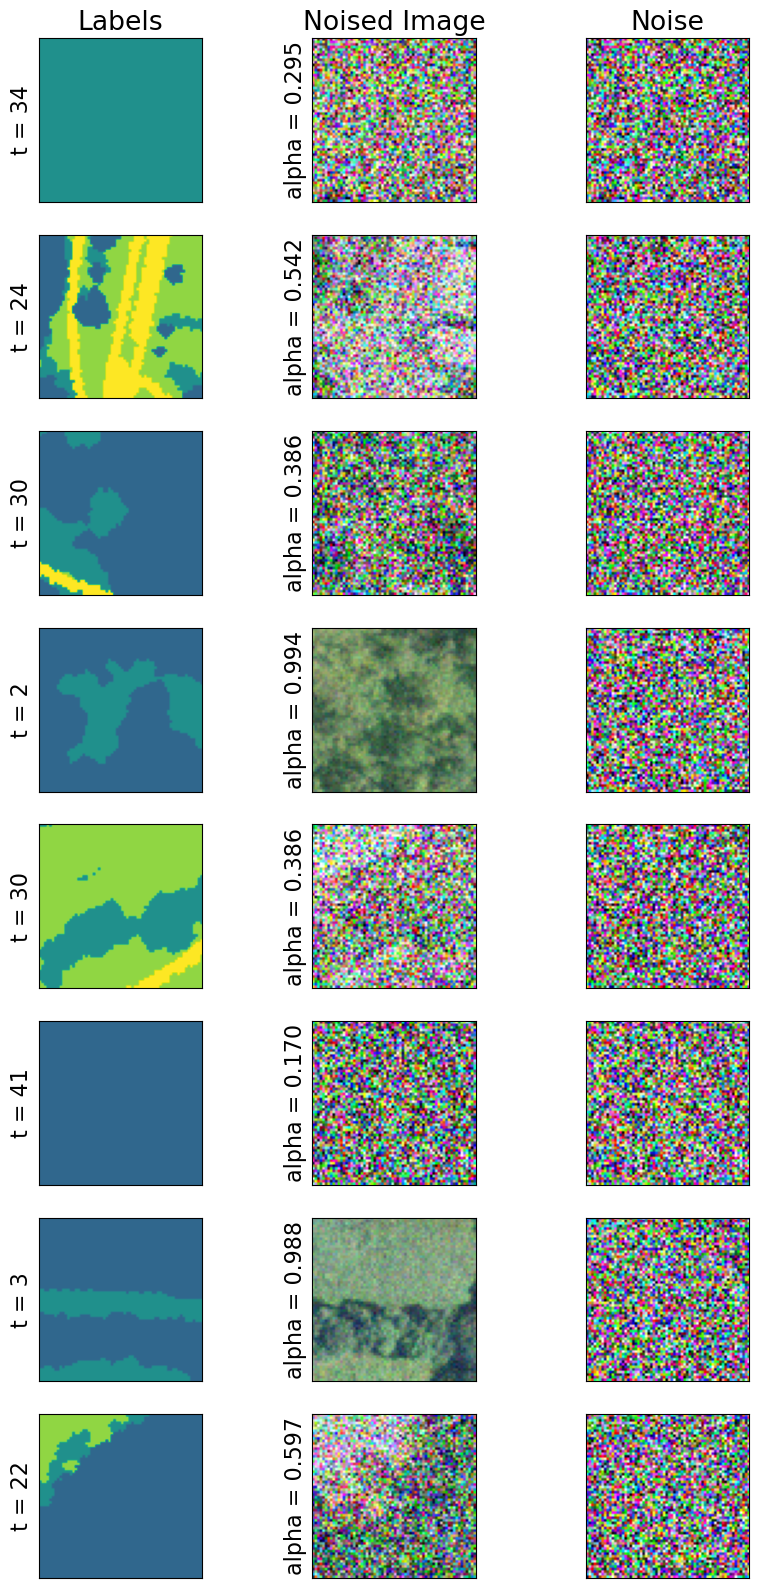

In [71]:
cols = 10


for i0, i1 in ds.take(1):
    L = i0['label_input']
    T = i0['time_input']
    I = i0['image_input']
    N = i1
    n_samples = L.shape[0]

    fig, axs = plt.subplots(n_samples, 3, figsize=(10,20))
    [64, 64, 26]
    for i in range(n_samples):
        axs[i,0].imshow(np.argmax(L.numpy()[i,:,:,:], axis=-1), vmin=0, vmax=6)
        axs[i,0].set_xticks([])
        axs[i,0].set_yticks([])
        axs[i,0].set_ylabel('t = %d'%T.numpy()[i,0])

        axs[i,1].imshow(convert_image(I.numpy()[i,:,:,:]))
        axs[i,1].set_xticks([])
        axs[i,1].set_yticks([])

        axs[i,1].set_ylabel('alpha = %.3f'%alpha[T.numpy()[i,0]])
        axs[i,2].imshow(convert_image(N.numpy()[i,:,:,:]))
        axs[i,2].set_xticks([])
        axs[i,2].set_yticks([])

        if i == 0:
            axs[i,0].set_title('Labels')
            axs[i,1].set_title('Noised Image')
            axs[i,2].set_title('Noise')
        

## Test Positional Encoder

In [37]:
# Create a simple model
input = Input(shape=(1,), dtype=tf.dtypes.int32)
pe = PositionEncoder(50, 30)
tensor = pe(input)
m = Model(inputs=input, outputs=tensor)

In [38]:
# Extract the embedding for visualization
pos = pe.embedding()

([<matplotlib.axis.YTick at 0x7f33505a9ad0>,
 [Text(0, 0, '0'),
  Text(0, 1, '1'),
  Text(0, 2, '2'),
  Text(0, 3, '3'),
  Text(0, 4, '4'),
  Text(0, 5, '5'),
  Text(0, 6, '6'),
  Text(0, 7, '7'),
  Text(0, 8, '8'),
  Text(0, 9, '9'),
  Text(0, 10, '10'),
  Text(0, 11, '11'),
  Text(0, 12, '12'),
  Text(0, 13, '13'),
  Text(0, 14, '14'),
  Text(0, 15, '15'),
  Text(0, 16, '16'),
  Text(0, 17, '17'),
  Text(0, 18, '18'),
  Text(0, 19, '19')])

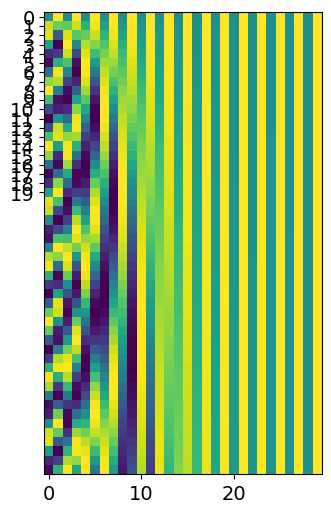

In [39]:
# Display the full embedding
plt.imshow(pos)
plt.yticks(range(20))

In [41]:
# b is the set of indices from the generator
# Test the extraction of the position encoding for each of the elements in the batch
vals = m.predict(t)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


In [43]:
t.numpy()

array([[35],
       [43],
       [32],
       [41],
       [ 6],
       [42],
       [19],
       [21]], dtype=int32)

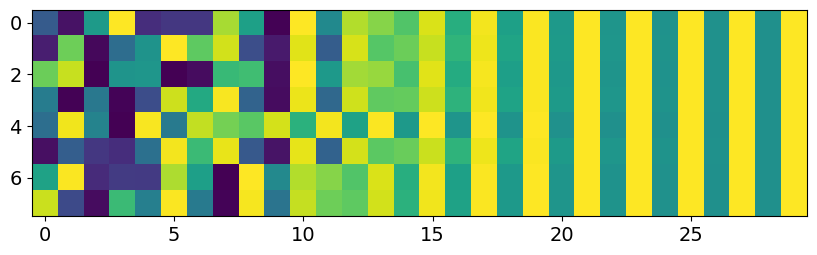

In [44]:
# Each row is the positional embedding for the 8 examples
plt.imshow(vals)

### Expanding a positional embedding
We have one positional embedding for every example.  Now we want to copy this embedding to every pixel.

Note that we are executing this example in __eager mode__, but these tf operators take as input proper TF Tensors and return TF Tensors, so they can be part of the model that you construct.

In [45]:
vals2 = tf.expand_dims( tf.expand_dims(vals, axis=1), axis=1)

In [46]:
vals2.shape

TensorShape([8, 1, 1, 30])

In [47]:
vals3 = tf.tile(vals2, [1,2,3,1])

In [48]:
vals3.shape

TensorShape([8, 2, 3, 30])

In [49]:
T.numpy()[4,0]

18

## Noise Schedule

In [58]:
beta, alpha, sigma = compute_beta_alpha(50, 0.0001, 0.1)

Text(0.5, 0, 'Time Step')

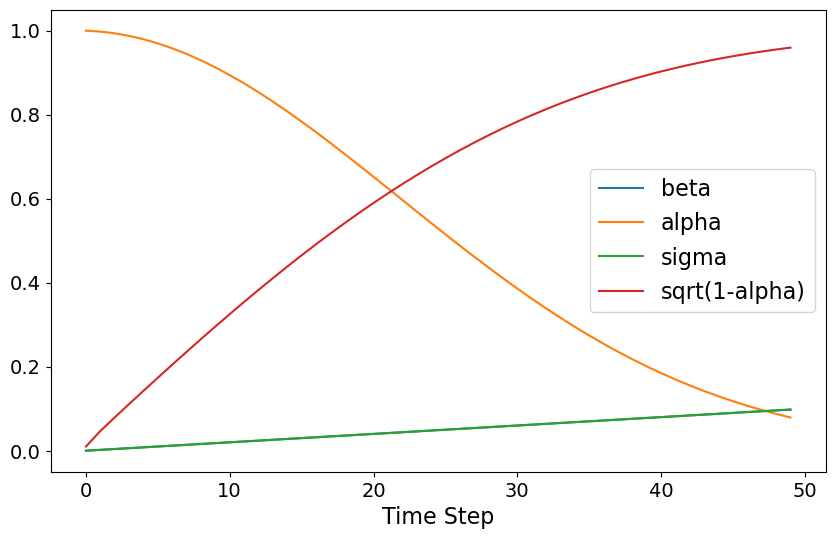

In [59]:
plt.plot(beta, label='beta')
plt.plot(alpha, label='alpha')
plt.plot(sigma, label='sigma')
plt.plot(np.sqrt(1-alpha), label='sqrt(1-alpha)')
plt.legend()
plt.xlabel('Time Step')

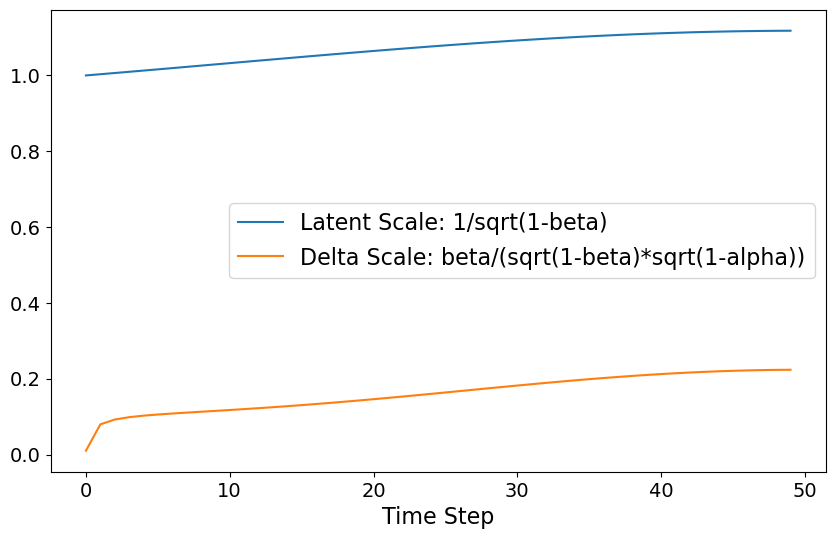

In [52]:
# Checking the factors used on the generation side
b2=1/np.sqrt(1-beta)
b3=beta / (np.sqrt(1-alpha) * np.sqrt(1-beta))
plt.plot(b2, label='Latent Scale: 1/sqrt(1-beta)')
plt.plot(b3, label='Delta Scale: beta/(sqrt(1-beta)*sqrt(1-alpha))')
plt.xlabel('Time Step')
plt.legend()

## Tensors for Random Number Generation

In [53]:
r = tf.random.uniform(shape=(1,), minval=0, maxval=20, dtype=tf.dtypes.int32)


In [54]:
print(r)

tf.Tensor([12], shape=(1,), dtype=int32)


In [55]:
r.numpy()

array([12], dtype=int32)